# Exercises XP: Introduction to LLMs

Use this guided notebook to follow the platform instructions step by step. Prefilled cells are ready to run; cells containing **TODO** markers need your input.


## 👩‍🏫👩🏿‍🏫 What you’ll learn
- Understand what Large Language Models (LLMs) can do.
- Review the Transformer architecture and the tokenization pipeline.
- Differentiate between pretraining and fine-tuning.
- Generate text with a pretrained language model.


## 🛠️ What you will create
- Markdown answers describing key NLP concepts.
- Python code that loads GPT-2 (or a similar causal LM) and performs basic tokenization and generation.


> **Learning point**
> Work through the exercises sequentially. Run installation cells only once, then focus on filling each TODO before executing the corresponding code.


## 🌟 Exercise 1 · What are Large Language Models?


### 1.1 Define LLMs
TODO: Explain in your own words what LLMs are and what kinds of tasks they are designed to solve.

Llms are models that understand humans languages, and able to answer, generate or predicts words from inputs by using transformers. Transformers is a pre-processing work.

### 1.2 Prefilled · install core libraries
Run once to install `transformers`, `torch`, and supporting utilities exactly as in the enoncé.


In [1]:
%pip install --quiet transformers matplotlib --upgrade


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1.3 Load GPT for causal text generation
Reuse the snippet from the platform: declare the model name, tokenizer, and model weights.


In [2]:
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline
import torch
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

model_name = 'gpt2'  # TODO: choose a causal LM checkpoint, e.g., 'gpt2'
tokenizer = AutoTokenizer.from_pretrained(model_name)   # TODO: load AutoTokenizer.from_pretrained(model_name)
model = AutoModelForCausalLM.from_pretrained(model_name)       # TODO: load AutoModelForCausalLM.from_pretrained(model_name)

if None in (model_name, tokenizer, model):
    raise ValueError("Fill in model_name, tokenizer, and model before continuing.")

print(f"\nModel '{model_name}' loaded successfully!")
print("""
GPT-2 is a causal language model, meaning it predicts the next word in a sequence.
It has been trained on a diverse dataset and can generate coherent, contextually relevant text.
""")


c:\Users\avigd\Desktop\GENAI\.venv2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 24541.67it/s]


Model 'gpt2' loaded successfully!

GPT-2 is a causal language model, meaning it predicts the next word in a sequence.
It has been trained on a diverse dataset and can generate coherent, contextually relevant text.



## 🌟 Exercise 2 · Transformer Architecture and Tokenization


TODO: Describe the tokenization process in your own words before coding.
The tokenization process transform the sentence by spliting into words or subwords. So one word can represent many tokens. 

Original Text: I’ll build the coziest lantern To help you cross the ocean I want to keep you dry I want to keep the spark And if the storm is hitting I’ll try to keep you steady And if I feel I‘m shaking I would return to practice
Tokens: ['I', 'âĢ', 'Ļ', 'll', 'Ġbuild', 'Ġthe', 'Ġco', 'z', 'iest', 'Ġlantern', 'ĠTo', 'Ġhelp', 'Ġyou', 'Ġcross', 'Ġthe', 'Ġocean', 'ĠI', 'Ġwant', 'Ġto', 'Ġkeep', 'Ġyou', 'Ġdry', 'ĠI', 'Ġwant', 'Ġto', 'Ġkeep', 'Ġthe', 'Ġspark', 'ĠAnd', 'Ġif', 'Ġthe', 'Ġstorm', 'Ġis', 'Ġhitting', 'ĠI', 'âĢ', 'Ļ', 'll', 'Ġtry', 'Ġto', 'Ġkeep', 'Ġyou', 'Ġsteady', 'ĠAnd', 'Ġif', 'ĠI', 'Ġfeel', 'ĠI', 'âĢ', 'ĺ', 'm', 'Ġshaking', 'ĠI', 'Ġwould', 'Ġreturn', 'Ġto', 'Ġpractice']
Token IDs: [40, 447, 247, 297, 1382, 262, 763, 89, 6386, 41207, 1675, 1037, 345, 3272, 262, 9151, 314, 765, 284, 1394, 345, 5894, 314, 765, 284, 1394, 262, 9009, 843, 611, 262, 6388, 318, 9008, 314, 447, 247, 297, 1949, 284, 1394, 345, 11831, 843, 611, 314, 1254, 314, 447, 246, 76, 17275, 314, 561, 1441, 284, 

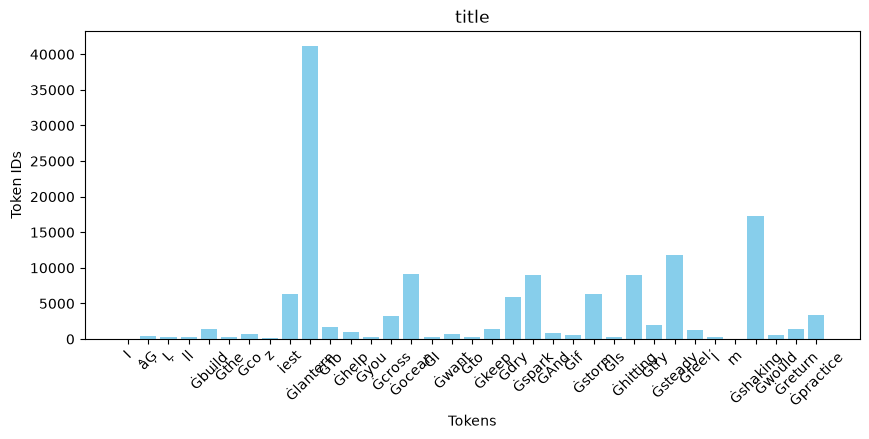

In [10]:
text = "I’ll build the coziest lantern To help you cross the ocean I want to keep you dry I want to keep the spark And if the storm is hitting I’ll try to keep you steady And if I feel I‘m shaking I would return to practice"
if text is None:
    raise ValueError("Define the variable `text` with a short sentence.")

tokens = tokenizer.tokenize(text)         # TODO: tokenize the input
token_ids = tokenizer.convert_tokens_to_ids(tokens)  # TODO: convert to ids

print(f"Original Text: {text}")
print(f"Tokens: {tokens}")
print(f"Token IDs: {token_ids}")

x_label = "Tokens"  # TODO: label for the x-axis (e.g., "Tokens")
y_label = "Token IDs"  # TODO: label for the y-axis (e.g., "Token IDs")
title = "title"    # TODO: chart title

if None in (x_label, y_label, title):
    raise ValueError("Set x_label, y_label, and title before plotting.")

plt.figure(figsize=(10, 4))
plt.bar(tokens, token_ids, color="skyblue")
plt.xlabel(x_label)
plt.ylabel(y_label)
plt.title(title)
plt.xticks(rotation=45)
plt.show()


## 🌟 Exercise 3 · Token IDs and special prefixes


In [14]:
if 'tokens' not in globals() or 'token_ids' not in globals():
    raise ValueError("Run Exercise 2 to define `tokens` and `token_ids` first.")

# TODO: print the token along with its numeric id
# raise NotImplementedError("Iterate over `tokens` and `token_ids`, printing each mapping.")
for k,v in zip(tokens, token_ids):
    print(f"{v} - {k}")


40 - I
447 - âĢ
247 - Ļ
297 - ll
1382 - Ġbuild
262 - Ġthe
763 - Ġco
89 - z
6386 - iest
41207 - Ġlantern
1675 - ĠTo
1037 - Ġhelp
345 - Ġyou
3272 - Ġcross
262 - Ġthe
9151 - Ġocean
314 - ĠI
765 - Ġwant
284 - Ġto
1394 - Ġkeep
345 - Ġyou
5894 - Ġdry
314 - ĠI
765 - Ġwant
284 - Ġto
1394 - Ġkeep
262 - Ġthe
9009 - Ġspark
843 - ĠAnd
611 - Ġif
262 - Ġthe
6388 - Ġstorm
318 - Ġis
9008 - Ġhitting
314 - ĠI
447 - âĢ
247 - Ļ
297 - ll
1949 - Ġtry
284 - Ġto
1394 - Ġkeep
345 - Ġyou
11831 - Ġsteady
843 - ĠAnd
611 - Ġif
314 - ĠI
1254 - Ġfeel
314 - ĠI
447 - âĢ
246 - ĺ
76 - m
17275 - Ġshaking
314 - ĠI
561 - Ġwould
1441 - Ġreturn
284 - Ġto
3357 - Ġpractice


TODO: In plain language, explain what the `Ġ` prefix indicates in GPT-style vocabularies.
> 'Ġ' seems to represent a space character before the word

## 🌟 Exercise 4 · Generate simple text


Create a fresh prompt, run the generator, and observe how the model extends your sentence token by token.


In [15]:
generator = pipeline(
    "text-generation",
    model=model,
    tokenizer=tokenizer,
    device=0 if torch.cuda.is_available() else -1,
)

input_text = "Oh, the sun is up It’s another beautiful day To laugh it up In the ashes Oh, the sun is up And it’s lower than yesterday You fucked it up Please be quiet"
if input_text is None:
    raise ValueError("Set `input_text` before generating.")

gen_kwargs = {
    "max_new_tokens": 60,  # TODO: adjust if you want longer/shorter outputs
    "temperature": 0.8,    # TODO: tune sampling temperature
    "top_p": 0.95,
    "do_sample": True,
}

output_ids = generator(input_text, **gen_kwargs)  # TODO: call the generator
output_text = output_ids[0]["generated_text"]     # TODO: extract the text string

print(f"Input: {input_text}")
print(f"Generated Output: {output_text}")


[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'top_p', 'temperature', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=50) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Input: Oh, the sun is up It’s another beautiful day To laugh it up In the ashes Oh, the sun is up And it’s lower than yesterday You fucked it up Please be quiet
Generated Output: Oh, the sun is up It’s another beautiful day To laugh it up In the ashes Oh, the sun is up And it’s lower than yesterday You fucked it up Please be quiet Please be quiet Oh, the sun is up I․s another beautiful day To laugh it up Please be quiet Please be quiet Oh, the sun is up I․s another beautiful day To laugh it up Please be quiet Please be quiet Oh, the sun is up I․s another


> **Learning point**
> Compare the generated continuation with your expectations. Which knobs (temperature, max tokens) change the style the most?

> We can see many repetitions in loop after the end of the original sentence. To limitate it, we can set the temperature at 1.0 ~ 1.2

Here's a summary that can help you decide of how to fix these parameters:

![image.png](https://github.com/user-attachments/assets/a4c444d7-fab8-4f56-b7c7-00a15900cb5a)